#Antecedente

In [ ]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      !pip install --upgrade --force-reinstall numpy
      pbar.update(33)
      !pip install --upgrade --force-reinstall pandas
      pbar.update(66)
      !pip install --upgrade --force-reinstall mordred

      pbar.update(100)

  0%|          | 0/100 [00:00<?, ?it/s]

In [ ]:
!pip install rdkit
! pip install molplotly
! pip install dash==3.2.0

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sn
from rdkit.Chem import AllChem
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import Draw
from rdkit import DataStructs
from rdkit.ML.Cluster import Butina
from tqdm import tqdm
import warnings
from rdkit.Chem import PandasTools
from rdkit import Chem
from rdkit.Chem import rdFMCS
import molplotly
warnings.filterwarnings('ignore')
import plotly.express as px

#cargamos datos

In [ ]:
! gdown --id 1RtoyG9CiOHtrkERzGBORYDpdp7VIJXvO #Invoca al archivo desde Drive
# df = pd.read_excel("s_au.xlsx")#en formato excel
#conversion de excel a dataframe
df = pd.read_excel("Romina_mordred.xlsx")

/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:140: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1RtoyG9CiOHtrkERzGBORYDpdp7VIJXvO
To: /content/Romina_mordred.xlsx
100% 1.76M/1.76M [00:00<00:00, 56.2MB/s]


In [ ]:
# prompt: de df elimina al primera fila

df = df.iloc[1:].reset_index(drop=True)
df

,Número de Estructura,Cmpd,SMILES,Peso molecular (PM),IC50 (ug/mL),IC50 (ug),Molar,pEC50,Artículo y año,ABC,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2
0,2 HL60,7-chloro-3-(4-(4-nitrophenyl)piperazin-1-yl)qu...,N#Cc1nc2cc(Cl)ccc2nc1N1CCN(c2ccc([N+](=O)[O-])...,394.82,4,---,0.00001,4.994339,Bonaerense 1998,module 'numpy' has no attribute 'float'.\n`np....,...,10.313708,63.589830,394.094501,9.164988,2245,47,150,178,8.611111,6.138889
1,3 HL60,"6,7-dimethyl-3-(4-(4-nitrophenyl)piperazin-1-y...",Cc1cc2nc(C#N)c(N3CCN(c4ccc([N+](=O)[O-])cc4)CC...,388.43,4.61,---,0.000012,4.925612,Bonaerense 1998,module 'numpy' has no attribute 'float'.\n`np....,...,10.377701,64.831793,388.164774,7.921730,2456,50,156,186,9.472222,6.333333
2,4 HL60,N-Pentyl-Nitrofurantoin (NFP),CCCCCN1C(=O)CN(/N=C\c2ccc([N+](=O)[O-])o2)C1=O,308.29,---,3.2,0.01038,1.983809,Pharmacological Reports 2016,module 'numpy' has no attribute 'float'.\n`np....,...,9.733114,71.428332,308.112070,8.108212,1225,29,108,124,8.277778,5.027778
3,5 HL60,Doxorubicin,COc1cccc2c1C(=O)c1c(O)c3c(c(O)c1C2=O)C[C@@](O)...,543.5,---,0.02,3.67X10-5,4.436000,Pharmacological Reports 2016,module 'numpy' has no attribute 'float'.\n`np....,...,10.991157,77.031951,543.174061,7.987854,4392,83,220,275,15.451389,8.416667
4,6 HL60,Nitrofurantoin,O=C1CN(/N=C/c2ccc([N+](=O)[O-])o2)C(=O)N1,238.16,---,4.4,0.018475,1.733416,Pharmacological Reports 2016,module 'numpy' has no attribute 'float'.\n`np....,...,9.464750,65.041652,238.033819,10.349296,580,20,86,98,6.416667,3.722222
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98,100 HL60,"(E)-6-(hydroxyimino)-2,2-dimethyl-2,3,4,6-tetr...",CC1(C)CCC2=C(O1)c1ccccc1/C(=N\O)C2=O,257.29,3.2,---,0.012437,1.905273,J.Med.Chem 2007,module 'numpy' has no attribute 'float'.\n`np....,...,10.203703,53.293105,257.105193,7.561917,608,35,106,129,6.729167,4.083333
99,101 HL60,"2-(2-hydroxypropan-2-yl)-5-nitro-2,3-dihydrona...",CC(C)(O)C1Cc2c(O)c([N+](=O)[O-])c3ccccc3c2O1,289.29,12,---,0.041481,1.382152,J.Med.Chem 2007,module 'numpy' has no attribute 'float'.\n`np....,...,10.279077,69.788454,289.095023,8.030417,811,38,118,144,8.451389,4.361111
100,102 HL60,(E)-5-(3-(2-fluorophenyl)allyl)-4-methyl-N-(py...,Cc1nc(Nc2ccccn2)sc1C/C=C/c1ccccc1F,325.41,1.9,---,0.005839,2.233677,MDPI 2022,module 'numpy' has no attribute 'float'.\n`np....,...,9.787010,70.718093,325.104897,8.336023,1409,30,116,132,6.416667,5.138889
101,103 HL60,(E)-1-(1H-indol-3-yl)-N-(4-(oxoarsaneyl)phenyl...,O=[As]c1ccc(/N=C/c2c[nH]c3ccccc23)cc1,310.19,13.94,---,0.04494,1.347365,Natural Prod. Sci. 2016,module 'numpy' has no attribute 'float'.\n`np....,...,9.716133,66.100121,310.008734,10.333624,789,26,98,114,4.805556,4.305556


In [ ]:
# Function to draw molecules using rdkit
def draw_molecules(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol is not None:
            return Draw.MolToImage(mol) # Using MolToImage directly
        else:
            return None  # Handle invalid smiles
    except Exception as e:
        print(f"Error drawing molecule for {smiles}: {e}")
        return None

In [ ]:
# Apply the function to the 'smiles' column
df['Molecule Image'] = df['SMILES'].apply(draw_molecules)
# Display the DataFrame (optional - uncomment to see the images)
PandasTools.AddMoleculeColumnToFrame(df, smilesCol='SMILES')
#df.head(2)

In [ ]:
# prompt: quita los dos ultimos elementos de df
# df = df[:-2]

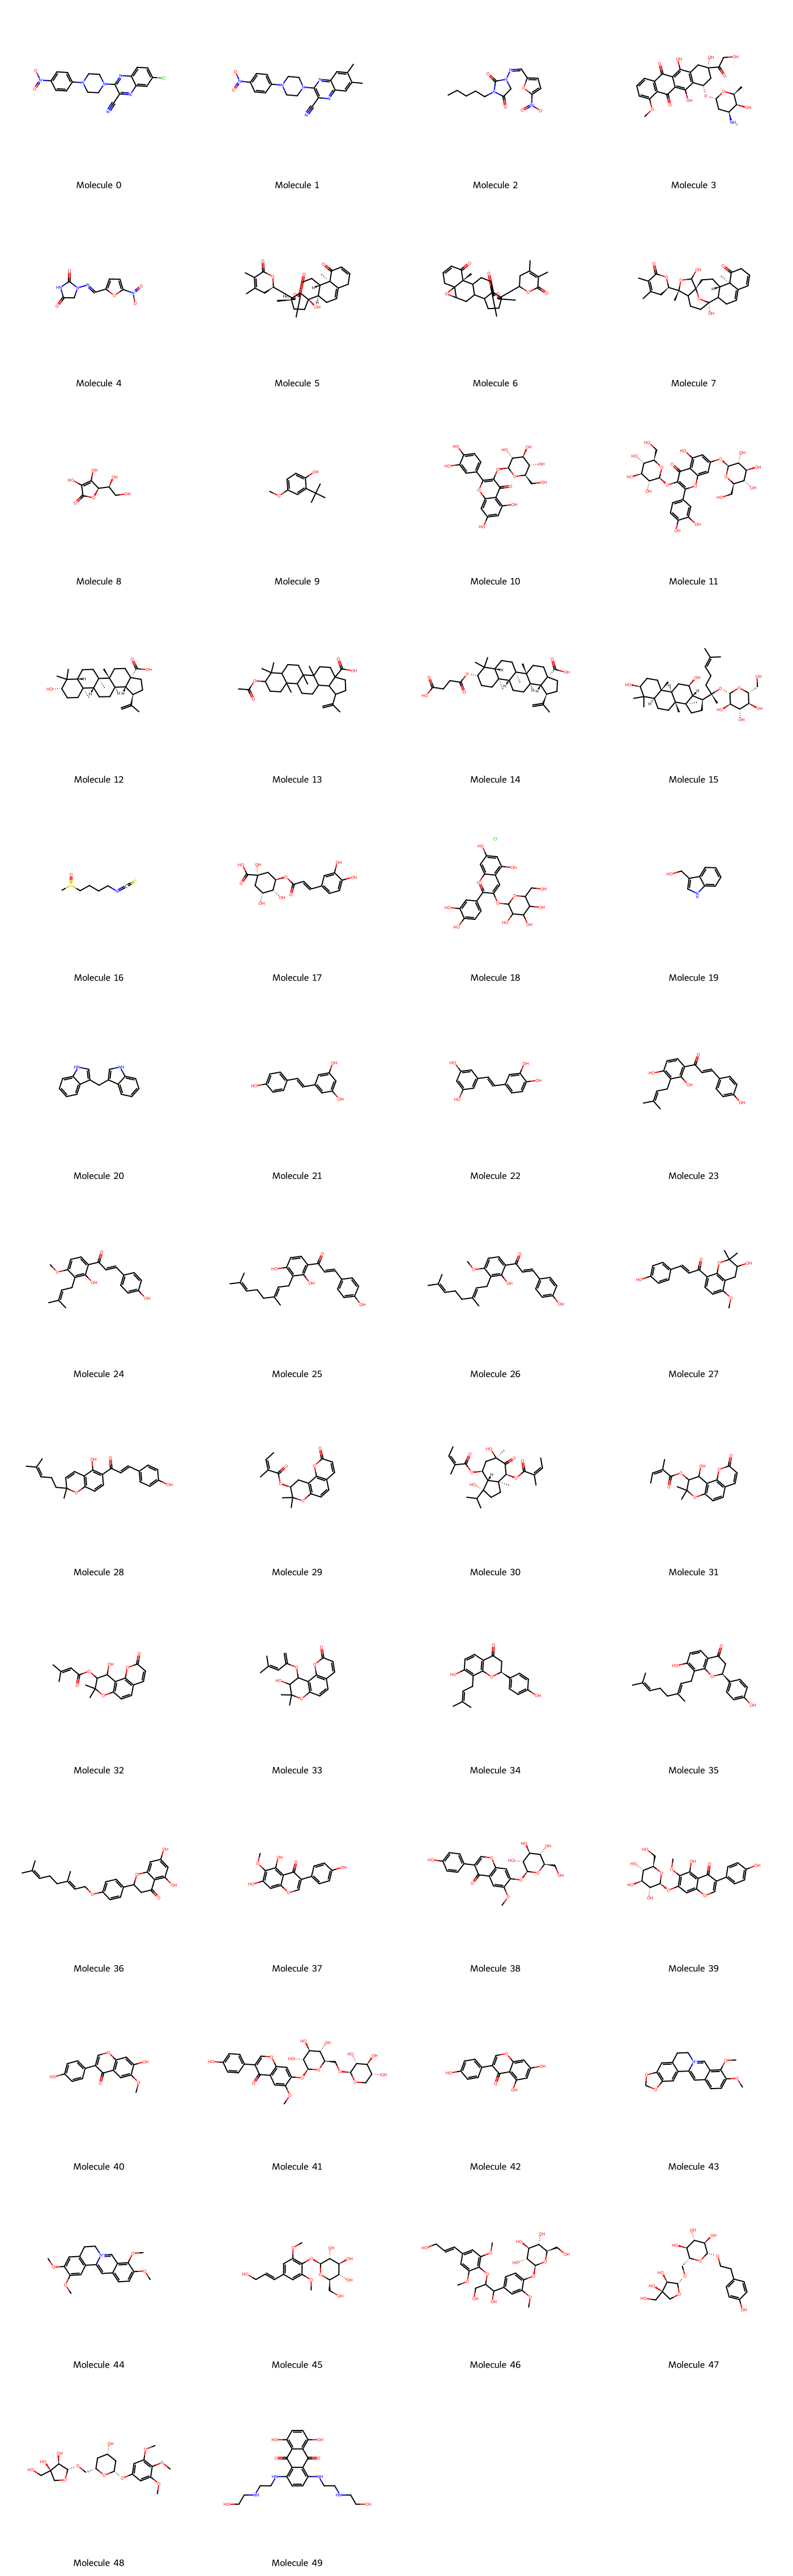

In [ ]:
# Usamos la función Draw.MolsToGridImage() para hacer la imagen de las moleculas en df

# Use Draw.MolsToGridImage to create a grid of molecule images
mols = [Chem.MolFromSmiles(smiles) for smiles in df['SMILES']]
grid_image = Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(350, 350), # Adjust molsPerRow and subImgSize as needed
                                  legends = [f"Molecule {i}" for i in range(0,len(mols))]
                                  )

# Display the grid image
grid_image

# Optionally, save the grid image
#grid_image.save('/content/molecules_grid.png')

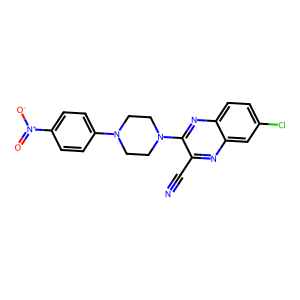

In [ ]:
from IPython.display import display
display(df['Molecule Image'][0])

In [ ]:
#fig = px.scatter(df, x=df.index, y='pIC50', color='G')
#fig.update_layout(plot_bgcolor='white')
#fig.show()

In [ ]:
# prompt: con plotly realiza una scatterplot de indice contra df.piC50

import plotly.express as px

fig = px.scatter(df, x=df.index, y='pEC50', #color='G'
                 width=900,
                 height=550
                 )
fig.update_layout(plot_bgcolor='white')
app = molplotly.add_molecules(
    fig=fig,
    df=df,
    smiles_col="SMILES",
    width=250,
    #caption_cols='G',
    #caption_cols=["y_pred", "y_true", "Molecular Weight"],
    #show_coords=False,
)


app.run(mode="inline", port=870, height=250)

#fig.show()

<IPython.core.display.Javascript object>

In [ ]:
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator

# --- Using MorganGenerator (does not directly populate bitInfo) ---
# Initialize the Morgan fingerprint generator
morgan_gen = GetMorganGenerator(radius=2, fpSize=2048)

In [ ]:
# Calculate fingerprints
def generate_fingerprint(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles)
        if mol is not None:
            fingerprint = morgan_gen.GetFingerprint(mol)
            return fingerprint
        else:
            return None  # Handle invalid smiles
    except Exception as e:
        print(f"Error generating fingerprint for {smiles}: {e}")
        return None

df['Fingerprint'] = df['SMILES'].apply(generate_fingerprint)

# Calculate Tanimoto similarity
tanimoto_matrix = np.zeros((len(df), len(df)))

for i in range(len(df)):
    for j in range(i, len(df)):
        if df['Fingerprint'][i] is not None and df['Fingerprint'][j] is not None:
            tanimoto_matrix[i, j] = DataStructs.TanimotoSimilarity(df['Fingerprint'][i], df['Fingerprint'][j])
            tanimoto_matrix[j, i] = tanimoto_matrix[i, j]

# Create a heatmap with plotly
df_tanimoto = pd.DataFrame(tanimoto_matrix)
fig = px.imshow(df_tanimoto,
                labels=dict(x="Molecule", y="Molecule", color="Tanimoto Similarity"),
                x=df.index,
                y=df.index,
                color_continuous_scale='Viridis')

fig.update_layout(title="Tanimoto Similarity Heatmap")
fig.show()

#Selección de moléculas

In [ ]:
# Tenems diferentes maneras de filtrar los datos con los índices
#filtered_df será el dataframe filtrado

#filtered_df = df.iloc[[8, 15]]
#_________________________________________________________________________________________________
# Filter elements based on index
#filtered_df = df[10:16]  # Example: Select rows with index 0,1, and 2. Modify the slice as needed
#_________________________________________________________________________________________________
# Filter rows with indices from 3 to 6 and 8 to 10
#filtered_df = pd.concat([df.iloc[3:7], df.iloc[8:11]]) #este es el ejmeplo
#____________________________________________________________________________________________________
#filtered_df = pd.concat([df.iloc[1:5], df.iloc[9:10]])
#filtered_df = pd.concat([df.iloc[[0, 2]], df[10:16]])
filtered_df = pd.concat([df.iloc[[#3,
                                  2,4, 14,
                                  4,7,
                                  60, 38
                                  #8,
                                  #11, 12,
                                  #14,15,16#,17,18
                                  ]]])
#filtered_df = pd.concat([df.iloc[[0]], df[11:13]])

##Funciones

In [ ]:
def find_mcs_multiple(smiles_list):
    mols = [Chem.MolFromSmiles(smiles) for smiles in filtered_df.SMILES]

    # Check for invalid smiles
    if any(mol is None for mol in mols):
        print("Invalid smiles string provided in the list.")
        return None, None, 0, False

    mcs = rdFMCS.FindMCS(mols)
    mcs_mol = Chem.MolFromSmarts(mcs.smartsString)

    return mcs_mol, mcs.smartsString, mcs.numAtoms, True

In [ ]:
def draw_multiple_mcs(smiles_list):
    mols = [Chem.MolFromSmiles(smiles) for smiles in filtered_df.SMILES]
    mcs_mol, mcs_smarts, mcs_atom_count, success = find_mcs_multiple(filtered_df.SMILES)
    if success:
        highlight_lists = [mol.GetSubstructMatch(mcs_mol) for mol in mols]

        # Get pIC50 values from the original df using indices from filtered_df
        pic50_values = [df.loc[idx, 'pEC50'] for idx in filtered_df.index]

        mols.append(mcs_mol)  # Add MCS to list for drawing
        highlight_lists.append([]) # No highlight for MCS itself

        # Create legends with pIC50 values
        legends = [f"{pic50:.2f}" for pic50 in pic50_values]
        legends.append("MCS") # Legend for MCS

        img = Draw.MolsToGridImage(mols,
                                   legends=legends,
                                   highlightAtomLists=highlight_lists,
                                   subImgSize=(450,450))
        return img
    else:
        return None

In [ ]:
comparison_image = draw_multiple_mcs(filtered_df.SMILES)

if comparison_image:
    comparison_image
else:
    print("MCS not found or invalid smiles provided.")

##resultados

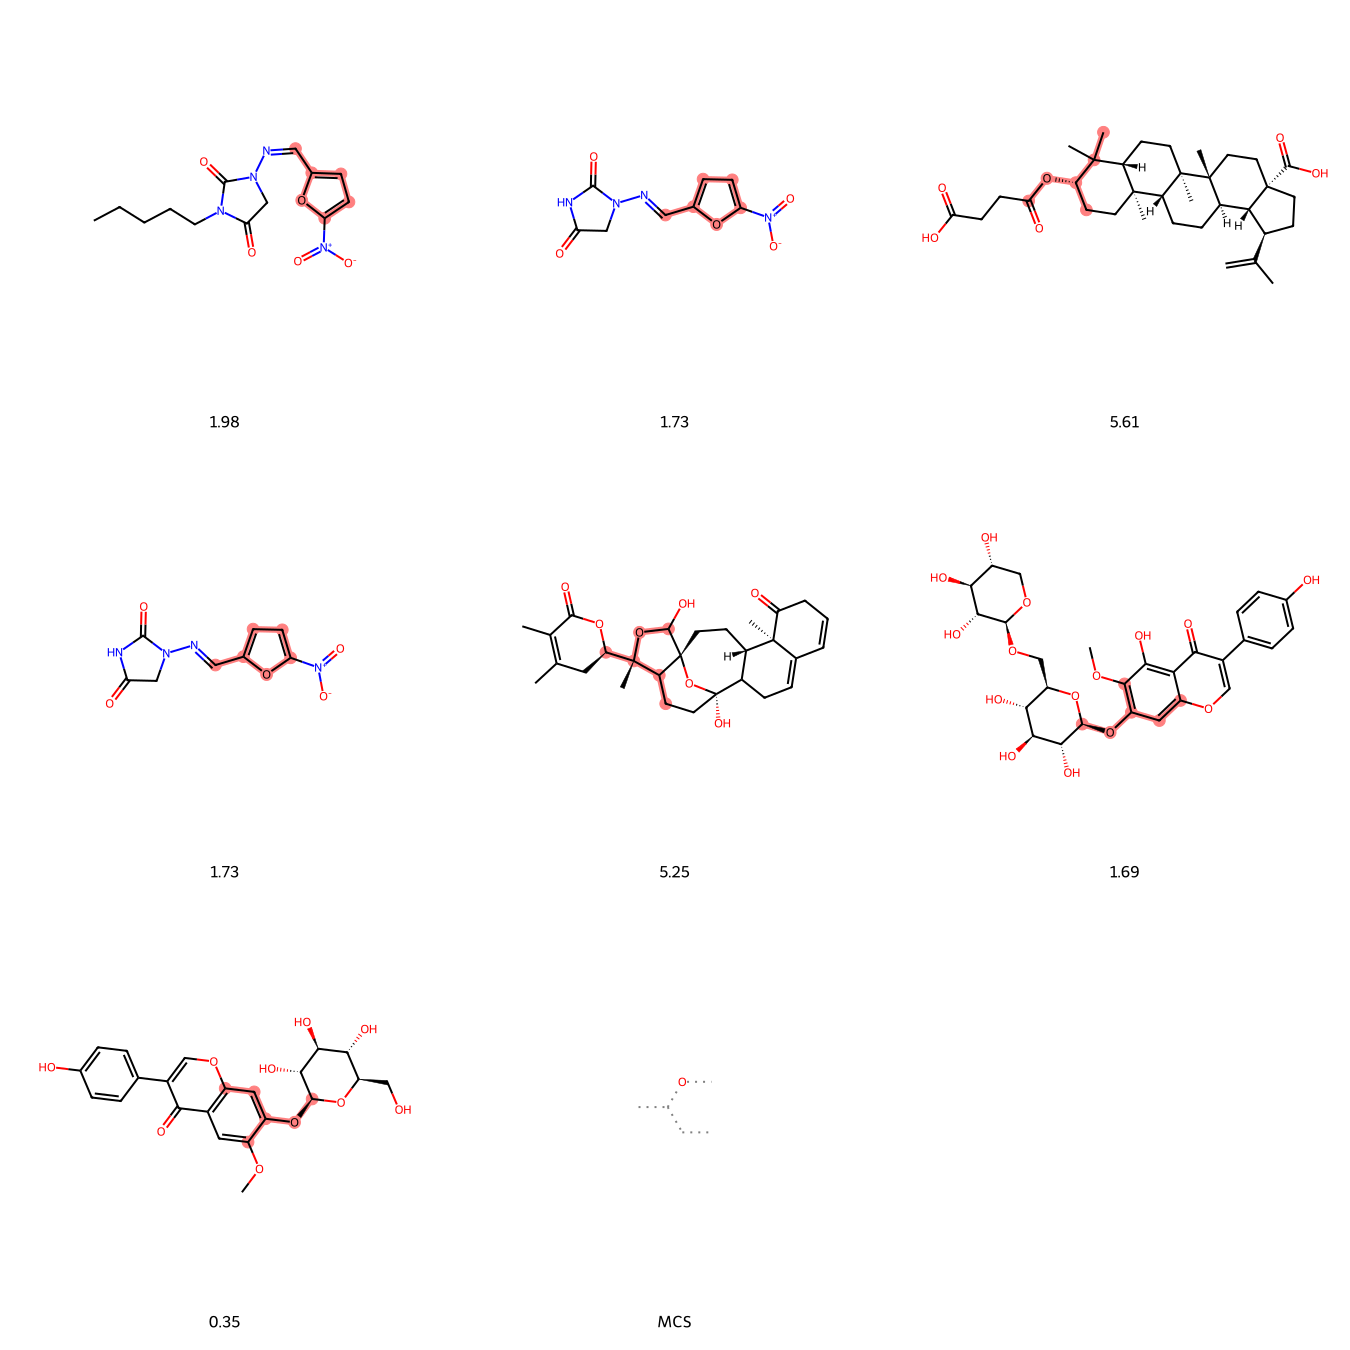

In [ ]:
comparison_image

Realizado por
Dr. Erick Correa
Maricarmen Cedillo
Enrique López
FES Zaragoza UNAM